In [ ]:
import pandas as pd
import numpy as np

# So we are able to see all columns
pd.set_option('display.max_rows', 2000)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
files = os.listdir(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics"
)
files

['sampled_all_systems.csv',
 'concat_flaml.csv',
 'concat_ag.csv',
 'result_monotonic_llama.csv',
 'result_monotonic_mistral.csv',
 'llama.csv',
 'mistral.csv',
 'result_equal_monotonic_ag_equal.csv',
 'result_monotonic_ag_equal.csv',
 'result_equal_monotonic_flaml_equal.csv',
 'result_monotonic_flaml_equal.csv',
 'result_equal_monotonic_rf_equal.csv',
 'result_monotonic_rf_equal.csv',
 'old_concat_rf.csv',
 'old_hpo_all_systems.csv',
 'concat_rf.csv',
 'hpo_all_systems.csv']

In [ ]:
# This is to simply obtain the dataset's type (multi or bin)
dataset_and_type = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/results_100_stratified.csv",
    sep=";"
)
dataset_and_type = dataset_and_type.loc[:, ["dataset"]]
dataset_and_type = dataset_and_type.drop_duplicates(subset=["dataset"], ignore_index=True)
dataset_and_type["pure_dataset"] = dataset_and_type["dataset"].str[:5]
dataset_and_type

,dataset,pure_dataset
0,ed_01_multi,ed_01
1,ed_02_multi,ed_02
2,ed_03_multi,ed_03
3,ed_04_multi,ed_04
4,ed_05_multi,ed_05
5,fn_01_multi,fn_01
6,fn_02_bin,fn_02
7,fn_03_multi,fn_03
8,fn_04_multi,fn_04
9,fn_05_multi,fn_05


## Llama

In [ ]:
df = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/output/statistics/llama.csv",
    sep=";"
)
df = df.merge(
    dataset_and_type,
    left_on="predicted_dataset",
    right_on="pure_dataset",
)
df = df.rename(
    columns={
        "predicted_dataset": "pure_predicted_dataset",
        "dataset": "predicted_dataset",
    }
)
df = df.assign(predicted_task=lambda df: df["predicted_dataset"].str[:2])
df["predicted_type"] = "bin"
multi_mask = df["predicted_dataset"].str.contains("multi")
df.loc[multi_mask, "predicted_type"] = "multi"

df

,pure_predicted_dataset,selected_llm,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,predicted_dataset,pure_dataset,predicted_task,predicted_type
0,ed_01,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.307054,0.448133,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['sadness', 'fear', 'disgust', 'anger', 'surpr...",ed_01_multi,ed_01,ed,multi
1,ed_01,LLAMA_3_2_3B_INSTRUCT,0,set(),{'---'},False,0.307054,0.381743,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['---', 'sadness', 'fear', 'disgust', 'anger',...",ed_01_multi,ed_01,ed,multi
2,ed_02,LLAMA_3_2_3B_INSTRUCT,5,set(),"{'reassurance', 'slutty', 'smug', 'compassion'...",False,0.342871,0.548982,"['love', 'sadness', 'fear', 'anger', 'surprise...","['reassurance', 'slutty', 'smug', 'compassion'...",ed_02_multi,ed_02,ed,multi
3,ed_02,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'happiness', 'nervousness', 'compassion', 'an...",False,0.342871,0.566905,"['love', 'sadness', 'fear', 'anger', 'surprise...","['compassion', 'anxiety', 'frustration', 'disg...",ed_02_multi,ed_02,ed,multi
4,ed_03,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'ambivalence', 'envyness', 'cautiousness', 'd...",False,0.294867,0.199409,"['annoyance', 'caring', 'sadness', 'disapprova...","['annoyance', 'ambivalence', 'caring', 'envyne...",ed_03_multi,ed_03,ed,multi
5,ed_03,LLAMA_3_2_3B_INSTRUCT,5,set(),"{'satire', 'discomfort', 'resilience', 'irrele...",False,0.294867,0.174021,"['annoyance', 'caring', 'sadness', 'disapprova...","['caring', 'ironic', 'perplexing', 'pride', 'o...",ed_03_multi,ed_03,ed,multi
6,ed_04,LLAMA_3_2_3B_INSTRUCT,0,set(),{'---'},False,0.904984,0.126210,"['hope', 'other', 'not_hope']","['hope', '---', 'other', 'not_hope']",ed_04_multi,ed_04,ed,multi
7,ed_04,LLAMA_3_2_3B_INSTRUCT,5,set(),set(),False,0.904984,0.493725,"['hope', 'other', 'not_hope']","['hope', 'other', 'not_hope']",ed_04_multi,ed_04,ed,multi
8,ed_05,LLAMA_3_2_3B_INSTRUCT,0,set(),"{'nan', '---'}",False,0.341667,0.291667,"['sadness', 'fear', 'anticipation', 'anger', '...","['---', 'sadness', 'fear', 'anticipation', 'an...",ed_05_multi,ed_05,ed,multi
9,ed_05,LLAMA_3_2_3B_INSTRUCT,5,set(),{'---'},False,0.341667,0.291667,"['sadness', 'fear', 'anticipation', 'anger', '...","['---', 'sadness', 'fear', 'anticipation', 'an...",ed_05_multi,ed_05,ed,multi


## 1. Evaluating Llama

### 1.1 Frequency based on hold_out_f1_score

#### 1.1.1 Task/Type

In [ ]:
df.groupby(["predicted_task", "predicted_type"], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type
ed              multi             0.352246
fn              bin               0.613792
                multi             0.237596
hs              bin               0.707412
                multi             0.441663
pc              bin               0.800058
                multi             0.440187
sd              bin               0.588542
                multi             0.377333
ua              multi             0.271394
Name: hold_out_f1_score, dtype: float64

#### 1.1.2 Type

In [ ]:
df.groupby(["predicted_type"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_type,
bin,0.715681
multi,0.330084


#### 1.1.3 Task

In [ ]:
df.groupby(["predicted_task"], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
predicted_task,
ed,0.352246
fn,0.312835
hs,0.636545
pc,0.640115
sd,0.447736
ua,0.271394


### 1.1.4 Task/Type/Number Of Examples

In [ ]:
df.groupby(["predicted_task", "predicted_type", "number_of_examples",], observed=False)["hold_out_f1_score"].mean()

predicted_task  predicted_type  number_of_examples
ed              multi           0                     0.313187
                                5                     0.391306
fn              bin             0                     0.613792
                                5                     0.613792
                multi           0                     0.248310
                                5                     0.226881
hs              bin             0                     0.703378
                                5                     0.711445
                multi           0                     0.379027
                                5                     0.504300
pc              bin             0                     0.896934
                                5                     0.703182
                multi           0                     0.478822
                                5                     0.401552
sd              bin             0                     0.770833
                                5                     0.406250
                multi           0                     0.349333
                                5                     0.405333
ua              multi           0                     0.251447
                                5                     0.291340
Name: hold_out_f1_score, dtype: float64

### 1.1.5 Task/Number of Examples

In [ ]:
df.groupby(["predicted_task", "number_of_examples",], observed=False)["hold_out_f1_score"].mean()

predicted_task  number_of_examples
ed              0                     0.313187
                5                     0.391306
fn              0                     0.321406
                5                     0.304263
hs              0                     0.616884
                5                     0.656206
pc              0                     0.711106
                5                     0.569125
sd              0                     0.489833
                5                     0.405639
ua              0                     0.251447
                5                     0.291340
Name: hold_out_f1_score, dtype: float64

### 1.1.6 Number of Examples

In [ ]:
df.groupby(["number_of_examples",], observed=False)["hold_out_f1_score"].mean()

,hold_out_f1_score
number_of_examples,
0,0.487738
5,0.477694


### 1.2 Frequency that non-sampled results (percentage=100) has the best results

In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic
best_results = (
    df.groupby(["selected_llm", "predicted_dataset"])
    .agg({"hold_out_f1_score": "max"})
    .reset_index()
    .rename(columns={"hold_out_f1_score": "max_hold_out_f1_score"})
    .merge(
        df,
        on=["selected_llm", "predicted_dataset"]
    )
    .query("hold_out_f1_score == max_hold_out_f1_score")
    .loc[:, ["selected_llm", "predicted_dataset", "number_of_examples", "hold_out_f1_score"]]
    .sort_values(["selected_llm", "predicted_dataset", "number_of_examples"])
    .drop_duplicates(["selected_llm", "predicted_dataset", "number_of_examples"], keep="first", ignore_index=True)
)
best_results

,selected_llm,predicted_dataset,number_of_examples,hold_out_f1_score
0,LLAMA_3_2_3B_INSTRUCT,ed_01_multi,5,0.448133
1,LLAMA_3_2_3B_INSTRUCT,ed_02_multi,0,0.566905
2,LLAMA_3_2_3B_INSTRUCT,ed_03_multi,0,0.199409
3,LLAMA_3_2_3B_INSTRUCT,ed_04_multi,5,0.493725
4,LLAMA_3_2_3B_INSTRUCT,ed_05_multi,0,0.291667
5,LLAMA_3_2_3B_INSTRUCT,ed_05_multi,5,0.291667
6,LLAMA_3_2_3B_INSTRUCT,fn_01_multi,0,0.134788
7,LLAMA_3_2_3B_INSTRUCT,fn_02_bin,0,0.687500
8,LLAMA_3_2_3B_INSTRUCT,fn_02_bin,5,0.687500
9,LLAMA_3_2_3B_INSTRUCT,fn_03_multi,0,0.181792


In [ ]:
best_results["number_of_examples"].value_counts()

,count
number_of_examples,
0,28
5,25


In [ ]:
# .25 .50
# .50 .75
# .75 1
# non_monotic: Set[str] -> datasets non-monotic

# number_of_examples = [0, 5]
# monotonic_analysis = pd.DataFrame()

monotonic_analysis =(
    df.sort_values(["selected_llm", "predicted_dataset", "number_of_examples"])
    .groupby(["selected_llm", "predicted_dataset"])
    ["hold_out_f1_score"]
    .apply(lambda x: x.is_monotonic_increasing)
    .reset_index()
    .rename(columns={"hold_out_f1_score": "monotonic"})
    .merge(
        df,
        on=["selected_llm", "predicted_dataset"]
    )
    .sort_values(["selected_llm", "predicted_dataset", "number_of_examples"])
)

monotonic_analysis


,selected_llm,predicted_dataset,monotonic,pure_predicted_dataset,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,pure_dataset,predicted_task,predicted_type
1,LLAMA_3_2_3B_INSTRUCT,ed_01_multi,True,ed_01,0,set(),{'---'},False,0.307054,0.381743,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['---', 'sadness', 'fear', 'disgust', 'anger',...",ed_01,ed,multi
0,LLAMA_3_2_3B_INSTRUCT,ed_01_multi,True,ed_01,5,set(),set(),False,0.307054,0.448133,"['sadness', 'fear', 'disgust', 'anger', 'surpr...","['sadness', 'fear', 'disgust', 'anger', 'surpr...",ed_01,ed,multi
3,LLAMA_3_2_3B_INSTRUCT,ed_02_multi,False,ed_02,0,set(),"{'happiness', 'nervousness', 'compassion', 'an...",False,0.342871,0.566905,"['love', 'sadness', 'fear', 'anger', 'surprise...","['compassion', 'anxiety', 'frustration', 'disg...",ed_02,ed,multi
2,LLAMA_3_2_3B_INSTRUCT,ed_02_multi,False,ed_02,5,set(),"{'reassurance', 'slutty', 'smug', 'compassion'...",False,0.342871,0.548982,"['love', 'sadness', 'fear', 'anger', 'surprise...","['reassurance', 'slutty', 'smug', 'compassion'...",ed_02,ed,multi
4,LLAMA_3_2_3B_INSTRUCT,ed_03_multi,False,ed_03,0,set(),"{'ambivalence', 'envyness', 'cautiousness', 'd...",False,0.294867,0.199409,"['annoyance', 'caring', 'sadness', 'disapprova...","['annoyance', 'ambivalence', 'caring', 'envyne...",ed_03,ed,multi
5,LLAMA_3_2_3B_INSTRUCT,ed_03_multi,False,ed_03,5,set(),"{'satire', 'discomfort', 'resilience', 'irrele...",False,0.294867,0.174021,"['annoyance', 'caring', 'sadness', 'disapprova...","['caring', 'ironic', 'perplexing', 'pride', 'o...",ed_03,ed,multi
6,LLAMA_3_2_3B_INSTRUCT,ed_04_multi,True,ed_04,0,set(),{'---'},False,0.904984,0.126210,"['hope', 'other', 'not_hope']","['hope', '---', 'other', 'not_hope']",ed_04,ed,multi
7,LLAMA_3_2_3B_INSTRUCT,ed_04_multi,True,ed_04,5,set(),set(),False,0.904984,0.493725,"['hope', 'other', 'not_hope']","['hope', 'other', 'not_hope']",ed_04,ed,multi
8,LLAMA_3_2_3B_INSTRUCT,ed_05_multi,True,ed_05,0,set(),"{'nan', '---'}",False,0.341667,0.291667,"['sadness', 'fear', 'anticipation', 'anger', '...","['---', 'sadness', 'fear', 'anticipation', 'an...",ed_05,ed,multi
9,LLAMA_3_2_3B_INSTRUCT,ed_05_multi,True,ed_05,5,set(),{'---'},False,0.341667,0.291667,"['sadness', 'fear', 'anticipation', 'anger', '...","['---', 'sadness', 'fear', 'anticipation', 'an...",ed_05,ed,multi


In [ ]:
monotonic_analysis.query("~monotonic").drop_duplicates(["predicted_dataset"], ignore_index=True)

,selected_llm,predicted_dataset,monotonic,pure_predicted_dataset,number_of_examples,missing_in_pred,extra_in_pred,only_one_predicted_label,f1_micro_majority,hold_out_f1_score,y_true_labels,y_pred_labels,pure_dataset,predicted_task,predicted_type
0,LLAMA_3_2_3B_INSTRUCT,ed_02_multi,False,ed_02,0,set(),"{'happiness', 'nervousness', 'compassion', 'an...",False,0.342871,0.566905,"['love', 'sadness', 'fear', 'anger', 'surprise...","['compassion', 'anxiety', 'frustration', 'disg...",ed_02,ed,multi
1,LLAMA_3_2_3B_INSTRUCT,ed_03_multi,False,ed_03,0,set(),"{'ambivalence', 'envyness', 'cautiousness', 'd...",False,0.294867,0.199409,"['annoyance', 'caring', 'sadness', 'disapprova...","['annoyance', 'ambivalence', 'caring', 'envyne...",ed_03,ed,multi
2,LLAMA_3_2_3B_INSTRUCT,fn_01_multi,False,fn_01,0,{'barely_true'},{'---'},False,0.200623,0.134788,"['false', 'half_true', 'pants_on_fire', 'mostl...","['false', '---', 'half_true', 'pants_on_fire',...",fn_01,fn,multi
3,LLAMA_3_2_3B_INSTRUCT,fn_03_multi,False,fn_03,0,set(),"{'most_true', '---'}",False,0.198683,0.181792,"['false', 'full_flop', 'half_flip', 'half_true...","['false', 'full_flop', 'half_flip', '---', 'ha...",fn_03,fn,multi
4,LLAMA_3_2_3B_INSTRUCT,fn_04_multi,False,fn_04,0,"{'outdated', 'unproven', 'legend', 'misattribu...",{'---'},False,0.564875,0.113368,"['unproven', 'false', 'false_and_true', 'corre...","['false', 'false_and_true', 'correct_attributi...",fn_04,fn,multi
5,LLAMA_3_2_3B_INSTRUCT,fn_07_multi,False,fn_07,0,{'refutation'},set(),False,0.369318,0.414773,"['insufficient_info', 'refutation', 'support']","['insufficient_info', 'support']",fn_07,fn,multi
6,LLAMA_3_2_3B_INSTRUCT,fn_10_multi,False,fn_10,0,set(),{'---'},False,0.516667,0.375000,"['out_of_scope', 'false', 'no_opinion', 'true']","['false', '---', 'no_opinion', 'out_of_scope',...",fn_10,fn,multi
7,LLAMA_3_2_3B_INSTRUCT,hs_04_bin,False,hs_04,0,set(),{'---'},False,0.906004,0.872489,"['toxic', 'not_toxic']","['---', 'toxic', 'not_toxic']",hs_04,hs,bin
8,LLAMA_3_2_3B_INSTRUCT,hs_08_bin,False,hs_08,0,set(),{'---'},False,0.930996,0.910451,"['not_hate', 'hate']","['not_hate', '---', 'hate']",hs_08,hs,bin
9,LLAMA_3_2_3B_INSTRUCT,hs_09_bin,False,hs_09,0,set(),set(),False,0.951535,0.873990,"['not_hate', 'hate']","['not_hate', 'hate']",hs_09,hs,bin


### 1.3 Dataset Label Imbalance

#### Creating imbalance dataset

In [ ]:
df_stats = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/analyses/df_stats.csv",
    sep=";",
)
df_stats = df_stats.query("method == 'gmm_random'")
df_imbalance = pd.DataFrame()
for pct in ["25", "50", "75", "100"]:
    df_imb = df_stats[["method", "dataset", f"label_imbalance_ratio_{pct}"]]
    df_imb = df_imb.rename(columns={f"label_imbalance_ratio_{pct}": "label_imbalance_ratio"})
    df_imb = df_imb.assign(percentage=int(pct))
    df_imbalance = pd.concat(
        [
            df_imbalance,
            df_imb
        ],
        axis=0,
    )
df_imbalance = df_imbalance.sort_values(["method", "dataset"])
df_imbalance = df_imbalance.rename(columns={"dataset": "task_and_number"})
df_imbalance["interval_ratio"] = pd.cut(
    df_imbalance["label_imbalance_ratio"],
    [0, 0.05, 0.1, 0.2, 0.3, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
)
df_imbalance

,method,task_and_number,label_imbalance_ratio,percentage,interval_ratio
0,gmm_random,ed_01,0.109756,25,"(0.1, 0.2]"
0,gmm_random,ed_01,0.069364,50,"(0.05, 0.1]"
0,gmm_random,ed_01,0.071698,75,"(0.05, 0.1]"
0,gmm_random,ed_01,0.072423,100,"(0.05, 0.1]"
1,gmm_random,ed_02,0.094602,25,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092692,50,"(0.05, 0.1]"
1,gmm_random,ed_02,0.091817,75,"(0.05, 0.1]"
1,gmm_random,ed_02,0.092517,100,"(0.05, 0.1]"
2,gmm_random,ed_03,0.003691,25,"(0.0, 0.05]"
2,gmm_random,ed_03,0.004213,50,"(0.0, 0.05]"


#### 1.3.1 Mean of hold_out_f1_score by interval_ratio

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        df,
        left_on=["task_and_number"],
        right_on=["pure_predicted_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
)

/tmp/ipython-input-1410855523.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


,hold_out_f1_score
interval_ratio,
"(0.0, 0.05]",0.261265
"(0.05, 0.1]",0.566860
"(0.1, 0.2]",0.371888
"(0.2, 0.3]",0.484585
"(0.3, 0.5]",0.433499
"(0.5, 0.6]",NaN
"(0.6, 0.7]",0.486938
"(0.7, 0.8]",0.609067
"(0.8, 0.9]",0.588574


#### 1.3.2 Mean of hold_out_f1_score by interval_ratio and task

In [ ]:
(
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        df,
        left_on=["task_and_number"],
        right_on=["pure_predicted_dataset"],
    )
    .assign(task=lambda df: df["pure_predicted_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
)

/tmp/ipython-input-3352470355.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


hold_out_f1_score
interval_ratio task                   
(0.0, 0.05]    ed             0.248342
               fn             0.118008
               hs             0.477153
               ua             0.273188
(0.05, 0.1]    ed             0.486441
               hs             0.634002
               pc             0.459135
(0.1, 0.2]     ed             0.291667
               hs             0.817071
               pc             0.379632
               ua             0.245072
(0.2, 0.3]     fn             0.308333
               hs             0.603070
               pc             0.542350
(0.3, 0.5]     fn             0.286382
               hs             0.654174
(0.6, 0.7]     sd             0.486938
(0.7, 0.8]     hs             0.609067
(0.8, 0.9]     fn             0.540084
               hs             0.856305
               sd             0.369333
(0.9, 1.0]     fn             0.533381
               hs             0.627470
               pc             0.800058
               ua             0.346769

# Insights

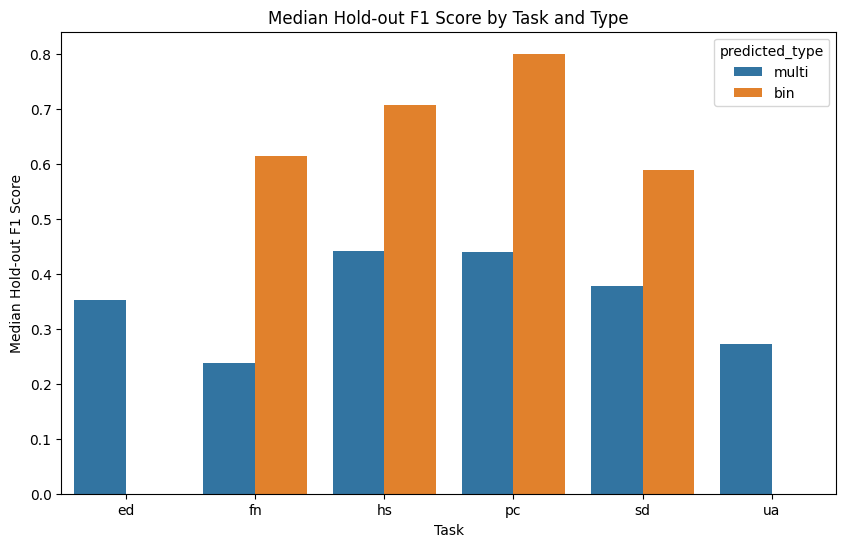

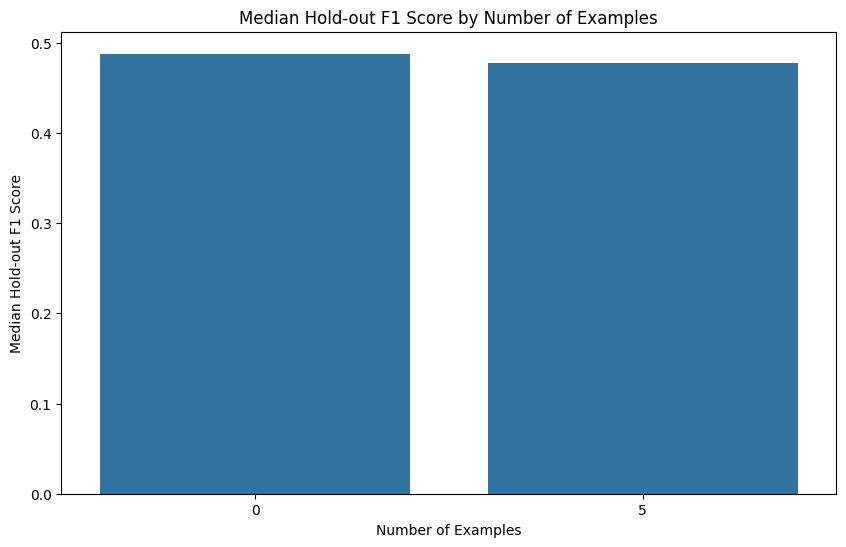

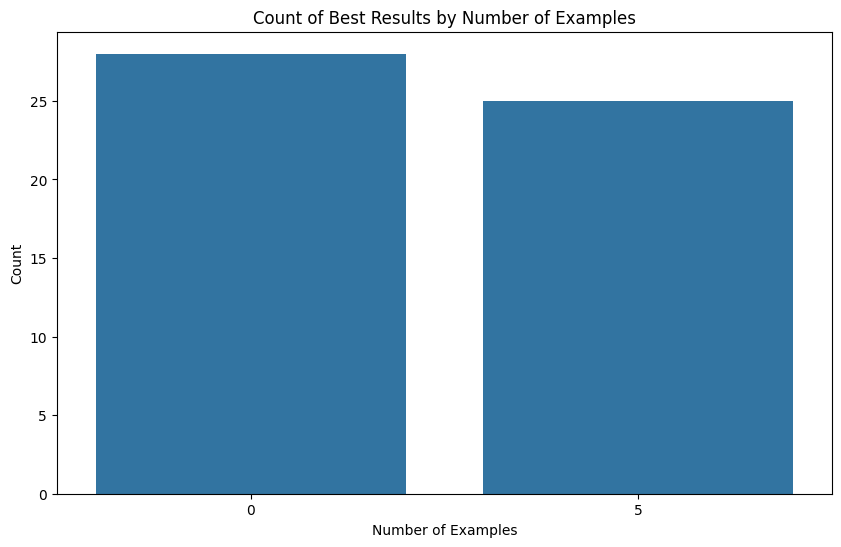

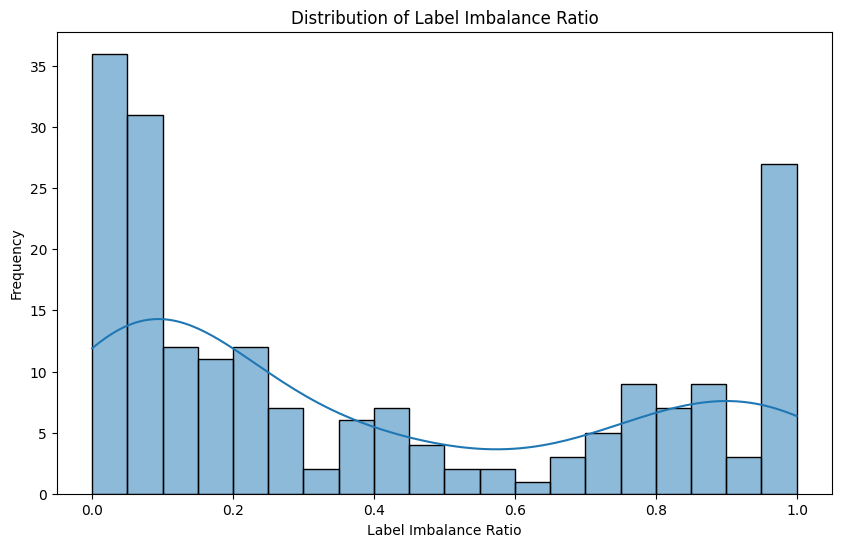

/tmp/ipython-input-3285065774.py:49: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("interval_ratio")


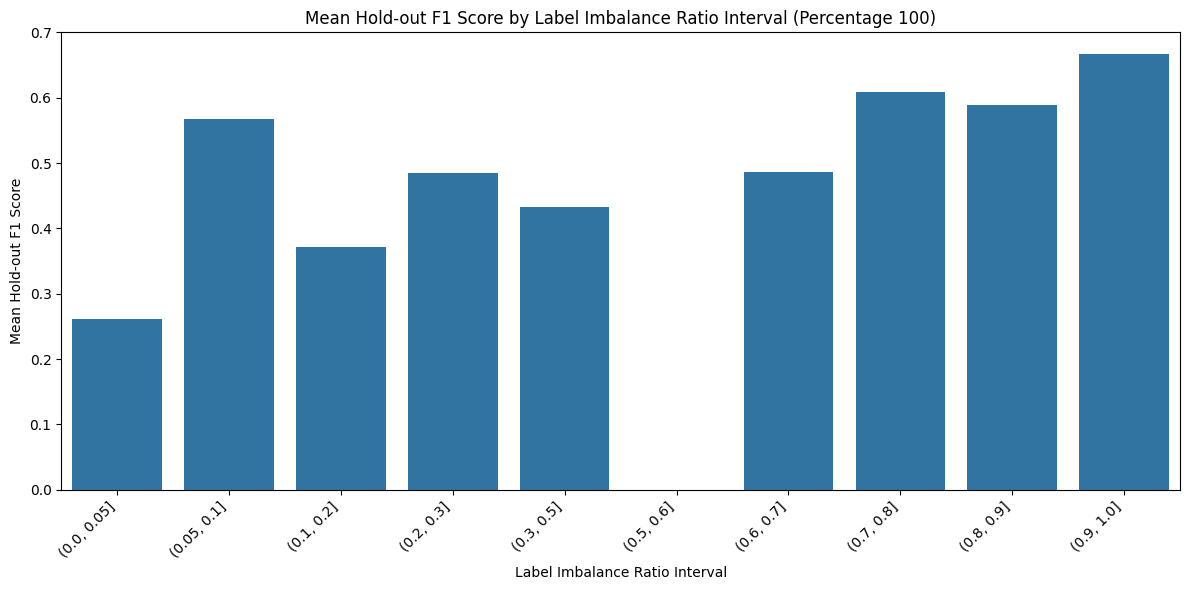

/tmp/ipython-input-3285065774.py:74: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["interval_ratio", "task"])


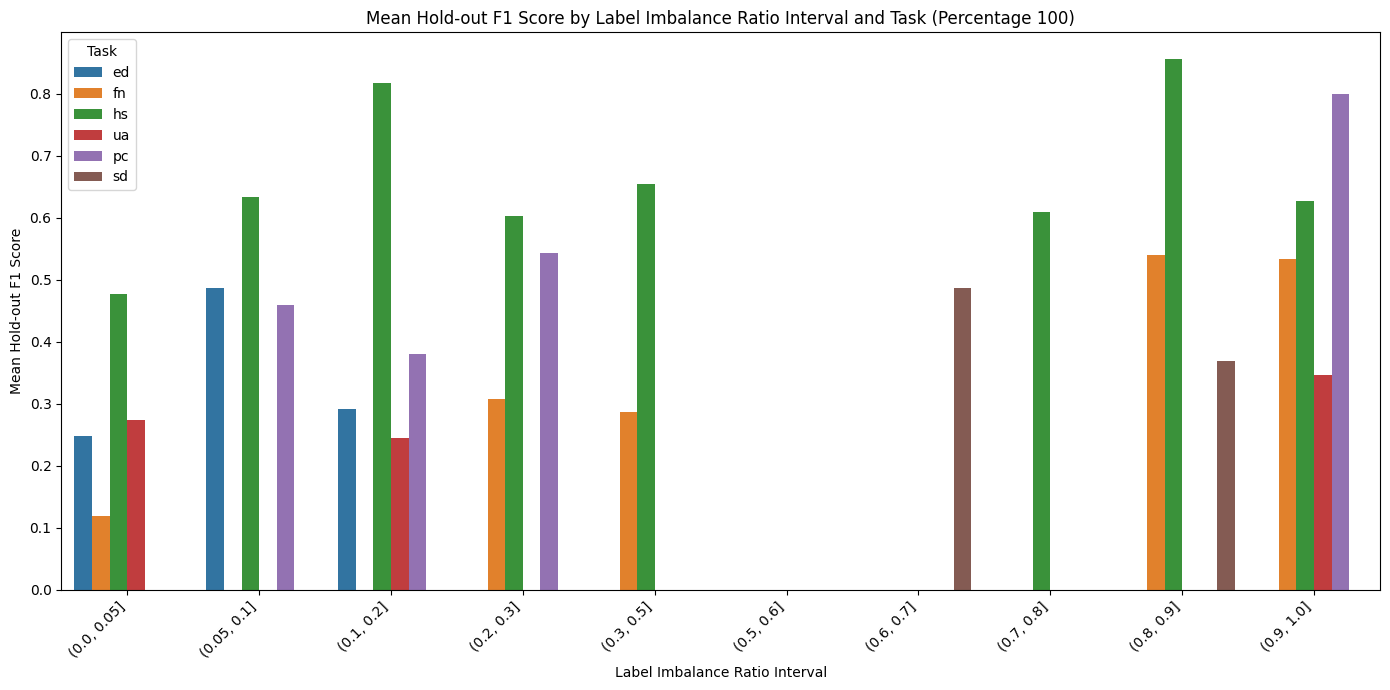

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting the median hold_out_f1_score by Task and Type
plt.figure(figsize=(10, 6))
sns.barplot(x="predicted_task", y="hold_out_f1_score", hue="predicted_type", data=df, estimator=np.mean, errorbar=None)
plt.title("Median Hold-out F1 Score by Task and Type")
plt.xlabel("Task")
plt.ylabel("Median Hold-out F1 Score")
plt.show()

# Plotting the median hold_out_f1_score by Number of Examples
plt.figure(figsize=(10, 6))
sns.barplot(x="number_of_examples", y="hold_out_f1_score", data=df, estimator=np.mean, errorbar=None)
plt.title("Median Hold-out F1 Score by Number of Examples")
plt.xlabel("Number of Examples")
plt.ylabel("Median Hold-out F1 Score")
plt.show()

# Plotting the count of best results by number_of_examples
plt.figure(figsize=(10, 6))
sns.countplot(x="number_of_examples", data=best_results)
plt.title("Count of Best Results by Number of Examples")
plt.xlabel("Number of Examples")
plt.ylabel("Count")
plt.show()

# Plotting the distribution of label imbalance ratio
plt.figure(figsize=(10, 6))
sns.histplot(df_imbalance["label_imbalance_ratio"], bins=20, kde=True)
plt.title("Distribution of Label Imbalance Ratio")
plt.xlabel("Label Imbalance Ratio")
plt.ylabel("Frequency")
plt.show()

# Plotting the mean hold_out_f1_score by interval_ratio for percentage == 100
imbalance_f1_mean = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        df,
        left_on=["task_and_number"],
        right_on=["pure_predicted_dataset"],
    )
    .groupby("interval_ratio")
    .agg({"hold_out_f1_score": "mean"})
    .reset_index()
)
plt.figure(figsize=(12, 6))
sns.barplot(x="interval_ratio", y="hold_out_f1_score", data=imbalance_f1_mean)
plt.title("Mean Hold-out F1 Score by Label Imbalance Ratio Interval (Percentage 100)")
plt.xlabel("Label Imbalance Ratio Interval")
plt.ylabel("Mean Hold-out F1 Score")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Plotting the mean hold_out_f1_score by interval_ratio and task for percentage == 100
imbalance_f1_task_mean = (
    df_imbalance.query("percentage == 100")
    [["task_and_number", "interval_ratio"]]
    .drop_duplicates()
    .sort_values(["task_and_number", "interval_ratio"])
    .merge(
        df,
        left_on=["task_and_number"],
        right_on=["pure_predicted_dataset"],
    )
    .assign(task=lambda df: df["pure_predicted_dataset"].str[:2])
    .groupby(["interval_ratio", "task"])
    .agg({"hold_out_f1_score": "mean"})
    .dropna()
    .reset_index()
)
plt.figure(figsize=(14, 7))
sns.barplot(x="interval_ratio", y="hold_out_f1_score", hue="task", data=imbalance_f1_task_mean)
plt.title("Mean Hold-out F1 Score by Label Imbalance Ratio Interval and Task (Percentage 100)")
plt.xlabel("Label Imbalance Ratio Interval")
plt.ylabel("Mean Hold-out F1 Score")
plt.xticks(rotation=45, ha='right')
plt.legend(title="Task")
plt.tight_layout()
plt.show()